# Convoluciones y clasificación de imágenes con MNIST

Práctica para inspeccionar filtros de una red convolucional preentrenada, visualizar sus convoluciones y clasificar los dígitos 0 a 9 del directorio `imagenes`. El cuaderno usa TensorFlow en CPU.

## Modelo y preparación

Se utiliza el modelo Keras preentrenado indicado en el cuaderno original. La primera capa convolucional recibe imágenes de MNIST en escala de grises, con tamaño 28 × 28 y valores normalizados entre 0 y 1. Ejecute las celdas desde la raíz del repositorio.

In [1]:
from pathlib import Path
import requests

model_path = Path("mnist_model.h5")
model_url = "https://huggingface.co/spaces/ayaanzaveri/mnist/resolve/main/mnist-model.h5"

if not model_path.exists():
    response = requests.get(model_url, timeout=60)
    response.raise_for_status()
    model_path.write_bytes(response.content)

print(f"Modelo disponible: {model_path.resolve()}")

Modelo disponible: C:\Users\diego\tarea07-clasificacion-mnist-Los-Visionarios\mnist_model.h5


In [2]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "-1"

import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import load_model

model = load_model(model_path)
(_, _), (x_test, y_test) = tf.keras.datasets.mnist.load_data()
x_test = x_test.astype("float32") / 255.0
x_test = x_test[..., np.newaxis]

loss, accuracy = model.evaluate(x_test, y_test, verbose=0)
print(f"Pérdida en MNIST de prueba: {loss:.4f}")
print(f"Exactitud en MNIST de prueba: {accuracy:.4f}")

Pérdida en MNIST de prueba: 0.0298
Exactitud en MNIST de prueba: 0.9935


## 1. Inspección de diez kernels

Se toman los primeros diez filtros de la primera capa `Conv2D`. Cada matriz muestra los pesos numéricos del filtro de entrada de escala de grises, además de su representación con colores. Los pesos pueden ser positivos o negativos; no son imágenes de dígitos.

Capa: conv2d; forma del banco de kernels: (3, 3, 1, 64)

Kernel 1:
[[-0.127   0.0612  0.1875]
 [ 0.0094  0.0684 -0.1561]
 [ 0.0773  0.1055 -0.0761]]

Kernel 2:
[[-0.0076 -0.0975 -0.0297]
 [-0.147   0.0235  0.1006]
 [ 0.0325  0.0986 -0.1725]]

Kernel 3:
[[ 0.0702 -0.211  -0.091 ]
 [ 0.0293 -0.0784 -0.1302]
 [ 0.1425  0.1111  0.1184]]

Kernel 4:
[[-0.212  -0.1374  0.2216]
 [-0.3146  0.033  -0.0064]
 [-0.1742 -0.1447 -0.0423]]

Kernel 5:
[[-0.1115  0.1551  0.0187]
 [-0.0387 -0.1988 -0.1316]
 [ 0.0793  0.0477  0.0221]]

Kernel 6:
[[ 0.147   0.1437  0.1988]
 [-0.0361 -0.0044  0.0709]
 [-0.2257 -0.1462 -0.0357]]

Kernel 7:
[[ 0.0047 -0.1027 -0.1601]
 [-0.0706  0.0487  0.2641]
 [ 0.0536 -0.0518  0.1599]]

Kernel 8:
[[-0.1548 -0.159   0.1037]
 [ 0.1362  0.1573  0.1184]
 [-0.1372 -0.0011 -0.0005]]

Kernel 9:
[[ 0.0907  0.1043 -0.0528]
 [-0.2048 -0.193   0.0404]
 [ 0.066   0.0605  0.1245]]

Kernel 10:
[[-0.1435  0.0946 -0.055 ]
 [ 0.0073  0.2407  0.137 ]
 [-0.0876 -0.1961  0.0594]]


C:\Users\diego\AppData\Local\Temp\ipykernel_18672\2097374150.py:25: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


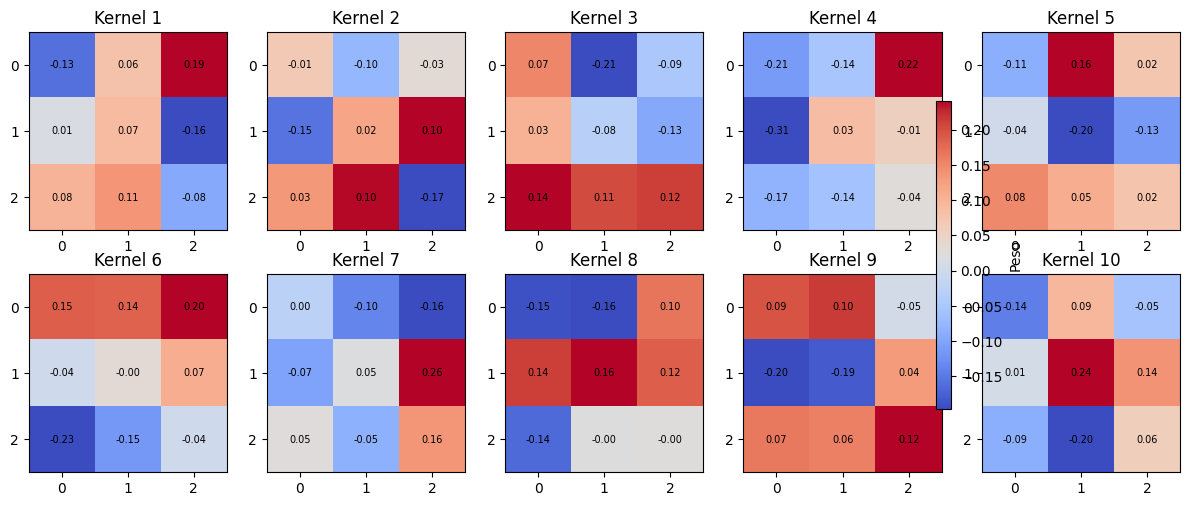

In [3]:
conv_layers = [layer for layer in model.layers if isinstance(layer, tf.keras.layers.Conv2D)]
if not conv_layers:
    raise ValueError("El modelo no contiene una capa Conv2D accesible.")

first_conv = conv_layers[0]
kernels, biases = first_conv.get_weights()
if kernels.shape[-1] < 10:
    raise ValueError("La primera capa convolucional debe tener al menos diez filtros.")

print(f"Capa: {first_conv.name}; forma del banco de kernels: {kernels.shape}")
for filter_index in range(10):
    print(f"\nKernel {filter_index + 1}:\n{np.array2string(kernels[:, :, 0, filter_index], precision=4)}")

fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for filter_index, ax in enumerate(axes.flat):
    kernel = kernels[:, :, 0, filter_index]
    image = ax.imshow(kernel, cmap="coolwarm")
    ax.set_title(f"Kernel {filter_index + 1}")
    ax.set_xticks(range(kernel.shape[1]))
    ax.set_yticks(range(kernel.shape[0]))
    for row in range(kernel.shape[0]):
        for column in range(kernel.shape[1]):
            ax.text(column, row, f"{kernel[row, column]:.2f}", ha="center", va="center", fontsize=7)
fig.colorbar(image, ax=axes, shrink=0.8, label="Peso")
fig.tight_layout()
plt.show()

## 2. Convolución de una imagen MNIST

`tf.nn.conv2d` aplica los diez filtros sin sumar los sesgos ni aplicar la activación de la capa. Así se observan las salidas directas de la operación de convolución. El relleno `SAME` conserva el tamaño espacial de 28 × 28.

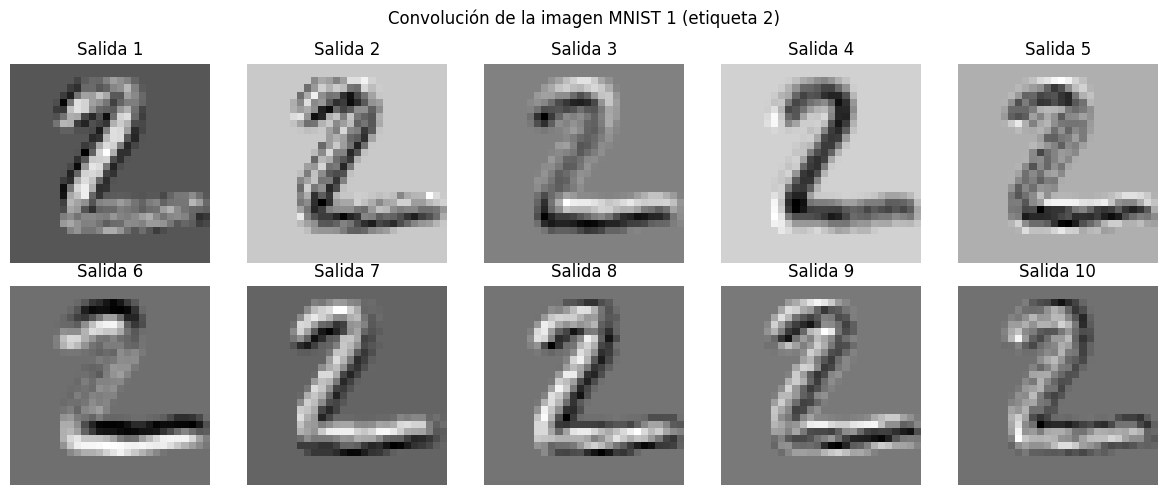

In [4]:
mnist_index = 1
mnist_image = x_test[mnist_index:mnist_index + 1]
ten_kernels = kernels[:, :, :, :10]
mnist_outputs = tf.nn.conv2d(mnist_image, ten_kernels, strides=1, padding="SAME")

fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for filter_index, ax in enumerate(axes.flat):
    ax.imshow(mnist_outputs[0, :, :, filter_index], cmap="gray")
    ax.set_title(f"Salida {filter_index + 1}")
    ax.axis("off")
fig.suptitle(f"Convolución de la imagen MNIST {mnist_index} (etiqueta {y_test[mnist_index]})")
fig.tight_layout()
plt.show()

## 3. Imágenes descargadas y evidencia de adquisición

Según la información proporcionada para esta práctica, los diez dígitos se descargaron de internet. El mosaico documenta los archivos procesados; para dejar evidencia verificable del proceso de adquisición, agregue las direcciones web de las fuentes y, si está disponible, una captura de las páginas de descarga. No se inventan enlaces ni se atribuye autoría a las imágenes.

Los archivos se llaman `img0.jpg` a `img9.jpg` y representan las clases indicadas por sus nombres. Son diseños de dígitos obtenidos de internet, no necesariamente ejemplos manuscritos como los de MNIST; por eso la comparación con el modelo es una prueba sobre este conjunto, no una medida general de desempeño.

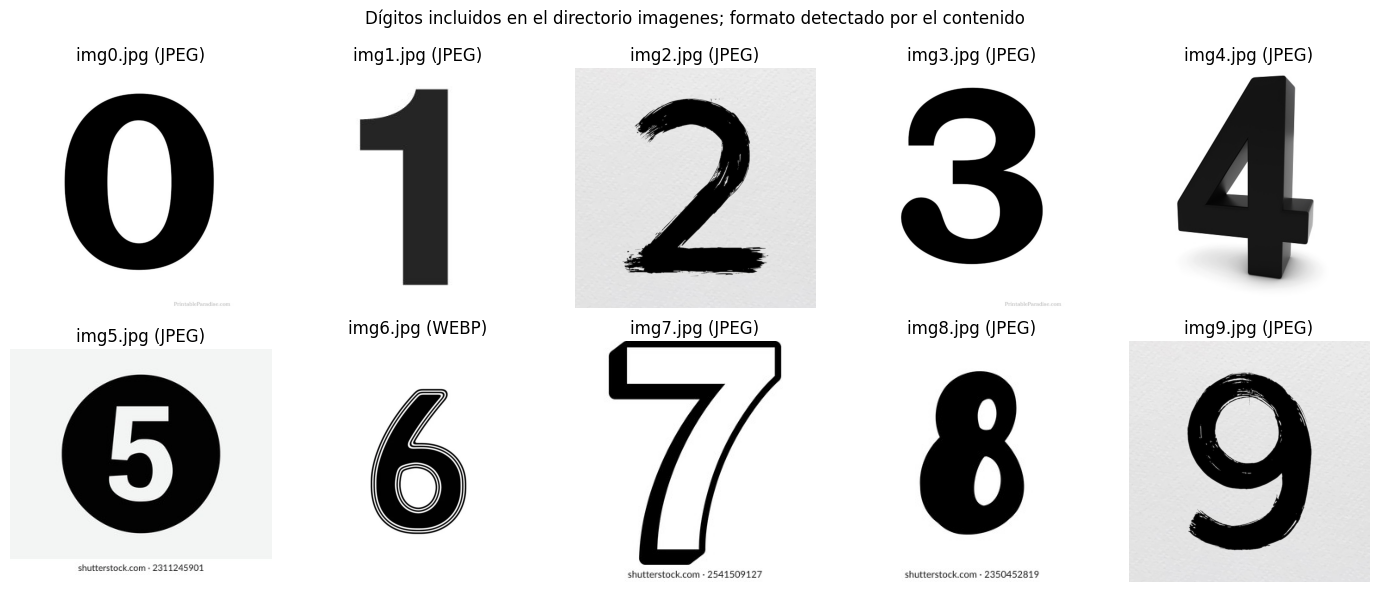

In [5]:
from PIL import Image

image_dir = Path("imagenes")
image_paths = sorted(image_dir.glob("*.jpg"))
if len(image_paths) < 10:
    raise ValueError(f"Se esperaban al menos diez archivos JPG; se encontraron {len(image_paths)} en {image_dir}.")
image_paths = image_paths[:10]

def load_rgb_image(image_path):
    """Abre una imagen por su contenido y la devuelve como RGB y su formato real."""
    try:
        with Image.open(image_path) as source:
            image_format = source.format
            image_rgb = np.asarray(source.convert("RGB"))
    except OSError as error:
        raise OSError(f"No se pudo leer la imagen {image_path}; compruebe que sea válida.") from error
    return image_rgb, image_format

fig, axes = plt.subplots(2, 5, figsize=(14, 6))
for path, ax in zip(image_paths[:10], axes.flat):
    original, actual_format = load_rgb_image(path)
    ax.imshow(original)
    ax.set_title(f"{path.name} ({actual_format})")
    ax.axis("off")
fig.suptitle("Dígitos incluidos en el directorio imagenes; formato detectado por el contenido")
fig.tight_layout()
plt.show()

### Tratamiento previo

El modelo espera una matriz monocromática de 28 × 28 con un canal, fondo oscuro, trazo claro e intensidades entre 0 y 1. Las imágenes se abren con Pillow según su formato real, se convierten a RGB y luego a escala de grises. Se invierte el contraste cuando el borde es claro, se recorta el contorno del dígito, se ajusta proporcionalmente a 20 × 20 y se centra en un lienzo de 28 × 28 con margen. Así se reduce el efecto de fondos y tamaños distintos. El estilo gráfico y los elementos adicionales de imágenes descargadas aún pueden diferir de MNIST.

In [6]:
def prepare_image(image_path):
    """Prepara un dígito como tensor gris 28x28x1 para el modelo."""
    image_rgb, _ = load_rgb_image(image_path)
    image = tf.convert_to_tensor(image_rgb, dtype=tf.float32) / 255.0
    image = tf.image.rgb_to_grayscale(image)

    border = tf.concat([image[0, :, 0], image[-1, :, 0], image[:, 0, 0], image[:, -1, 0]], axis=0)
    if float(tf.reduce_mean(border)) > 0.5:
        image = 1.0 - image

    foreground = tf.where(tf.squeeze(image, axis=-1) > 0.15)
    if int(tf.shape(foreground)[0]) == 0:
        raise ValueError(f"No se detectó el dígito en {image_path}.")
    top = int(tf.reduce_min(foreground[:, 0]))
    left = int(tf.reduce_min(foreground[:, 1]))
    bottom = int(tf.reduce_max(foreground[:, 0]))
    right = int(tf.reduce_max(foreground[:, 1]))
    digit = tf.image.crop_to_bounding_box(image, top, left, bottom - top + 1, right - left + 1)
    digit = tf.image.resize_with_pad(digit, 20, 20)
    return tf.pad(digit, [[4, 4], [4, 4], [0, 0]])

prepared_images = tf.stack([prepare_image(path) for path in image_paths[:10]])
print(f"Forma del lote: {prepared_images.shape}")
print(f"Tipo de dato: {prepared_images.dtype}")
print(f"Rango de intensidades: {float(tf.reduce_min(prepared_images)):.3f} a {float(tf.reduce_max(prepared_images)):.3f}")

Forma del lote: (10, 28, 28, 1)
Tipo de dato: <dtype: 'float32'>
Rango de intensidades: 0.000 a 1.000


### Predicciones para las diez imágenes

Se infiere el lote de diez imágenes y se compara la clase de mayor puntuación con el dígito indicado por el nombre del archivo (`img0` a `img9`). La exactitud describe solo estas diez imágenes descargadas y no debe generalizarse a todo MNIST.

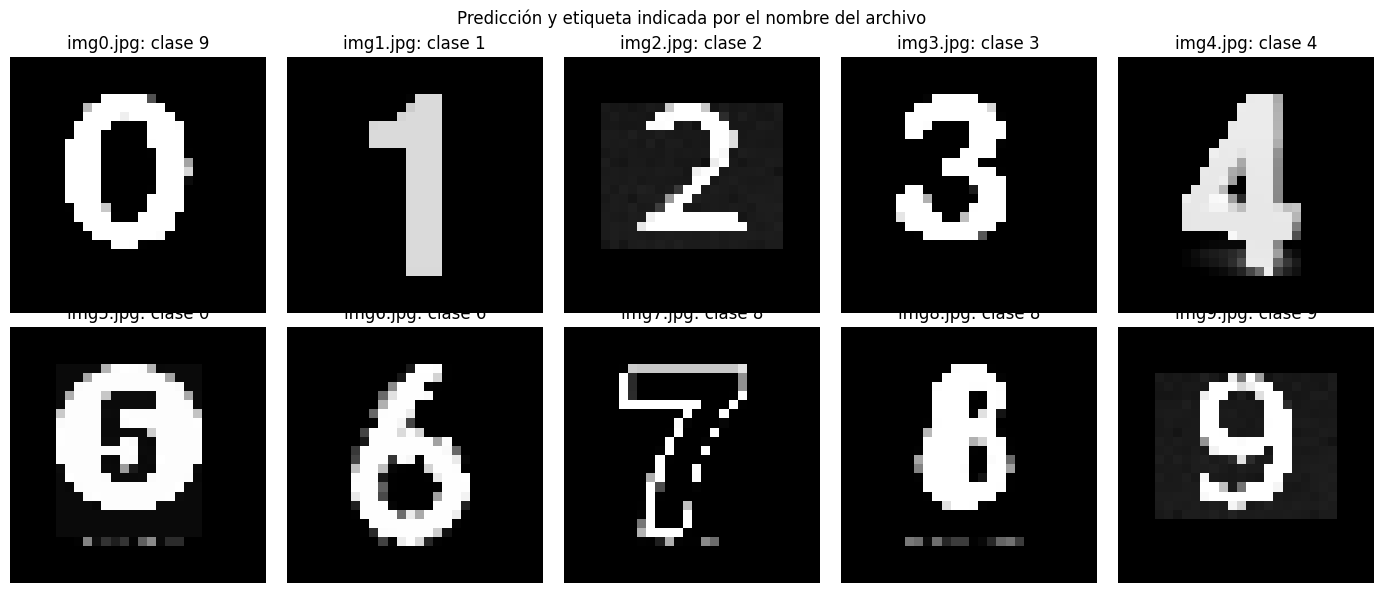

img0.jpg: esperado 0, predicho 9
img1.jpg: esperado 1, predicho 1
img2.jpg: esperado 2, predicho 2
img3.jpg: esperado 3, predicho 3
img4.jpg: esperado 4, predicho 4
img5.jpg: esperado 5, predicho 0
img6.jpg: esperado 6, predicho 6
img7.jpg: esperado 7, predicho 8
img8.jpg: esperado 8, predicho 8
img9.jpg: esperado 9, predicho 9
Exactitud en estas diez imágenes: 70.0%


In [7]:
predictions = model.predict(prepared_images, verbose=0)
predicted_digits = np.argmax(predictions, axis=1)

fig, axes = plt.subplots(2, 5, figsize=(14, 6))
for index, ax in enumerate(axes.flat):
    ax.imshow(prepared_images[index, :, :, 0], cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"{image_paths[index].name}: clase {predicted_digits[index]}")
    ax.axis("off")
fig.suptitle("Predicción y etiqueta indicada por el nombre del archivo")
fig.tight_layout()
plt.show()

for index, path in enumerate(image_paths):
    print(f"{path.name}: esperado {index}, predicho {predicted_digits[index]}")
print(f"Exactitud en estas diez imágenes: {np.mean(predicted_digits == np.arange(10)):.1%}")

## 4. Convolución de una imagen propia

Se repite la operación del ejercicio 2 con `img0.jpg` después del mismo tratamiento de escala de grises, ajuste de contraste y centrado del dígito.

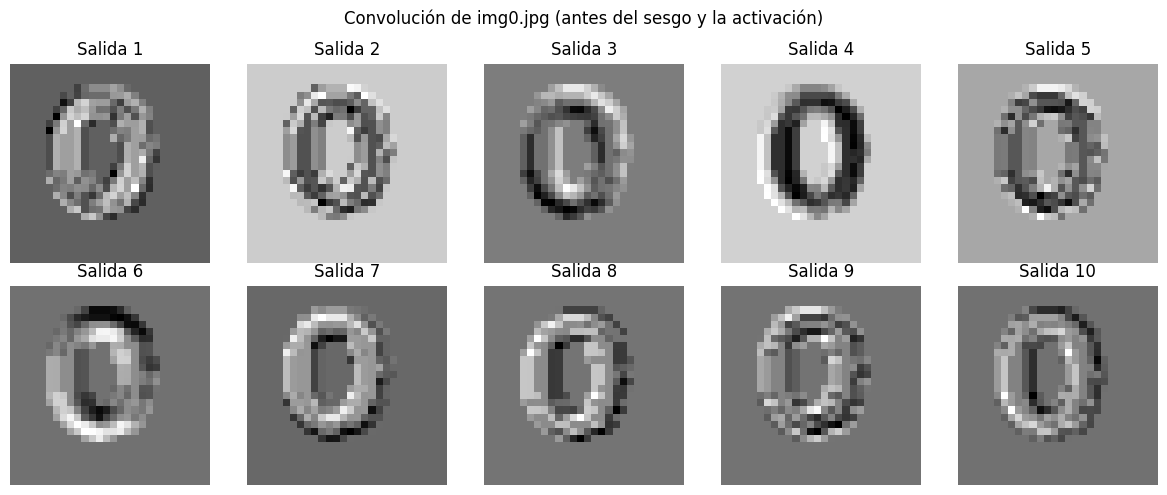

In [8]:
own_image = prepared_images[0:1]
own_outputs = tf.nn.conv2d(own_image, ten_kernels, strides=1, padding="SAME")

fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for filter_index, ax in enumerate(axes.flat):
    ax.imshow(own_outputs[0, :, :, filter_index], cmap="gray")
    ax.set_title(f"Salida {filter_index + 1}")
    ax.axis("off")
fig.suptitle(f"Convolución de {image_paths[0].name} (antes del sesgo y la activación)")
fig.tight_layout()
plt.show()

## Conclusiones y alcance

Los primeros diez filtros y sus respuestas se obtienen de la primera capa convolucional del modelo preentrenado. Las diez imágenes descargadas se convierten al formato de entrada del modelo y las predicciones se comparan con los dígitos indicados por sus nombres. El conjunto es pequeño y contiene diseños gráficos variados, así que los resultados no representan una evaluación general de MNIST. Para completar la evidencia de adquisición, deben agregarse las fuentes web de las imágenes.